# Test Notebook for Timeseries Analysis (Classification)

This notebook is used to implement and test some concepts before implementing them as .py files in the main repository. 

We start with defining as small subsample of accounts to work with and test all the implemenations on. This allows for quick iteration and easy visualisation of the outputs for human testing. 

For each time step, we look at all nodes that are currently part of the network. For these nodes, we calculate the features based on the second-order neighbourhood using the implementations in this repository for the three proceding time steps. This number three will also be the echo size (to keep experiments small and tractable). 

Hence, at each time step, we have defined a time series of historical data for the nodes. We implement a padding and masking algorithm that can pad those timeseries that don't have values for the full time period. One caviat here is that it is possible that at time step 3, node x has transactions at step 1 and step 3, but not at step 2. For this node, step 2 should be padded, meaning that padding is not just added at the end of the time series like in normal sentence/time series analysis. 

Finally, we look at implementing two methods that take in the time series and padding, namely an LSTM model and a Transformer model. 

Functions and classes are already defined an implemented here as a first test. All implementations are done as simple as possible to provide understandible code that can be replicated and reused. We don't aim to have long, complex code that is fully production ready and includes small tests inside the code. 

In [1]:
# --- Setup ----------------------------------------------------------------
# Run from the repo root: the loaders use paths like ./data/ and config/.
import os, sys
while not (os.path.isdir("src") and os.path.isdir("data")) and os.getcwd() != "/":
    os.chdir("..")
assert os.path.isdir("src"), "Run this notebook from inside the SPaRTA repo."
sys.path.append(os.getcwd())
print("Working dir:", os.getcwd())

import json, random
import numpy as np
import pandas as pd
import networkx as nx
import xgboost  # NOTE: import xgboost BEFORE torch — on macOS both ship an OpenMP
                # runtime and the torch-first order segfaults the kernel (so the
                # XGBoost baseline below stays importable). Mirrors experiment_features.py.
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score

# Reuse the repo's building blocks (nothing here is re-implemented).
from src.data.network_data_loader import load_transactions, load_network_time, define_ML_labels
from src.data.utils.dates import define_dates
from src.utils.graph_processing import graph_community
from src.methods.neighbourhood_picture import node_measures
from src.methods.measure_calculation import keys_to_include  # 90 feature columns, canonical order

# --- Constants (kept small & tractable for a test) ------------------------
SEED = 1997
DATASET, TYPE_DATASET = "AMLWorld", "HI-Small"
T = 3                      # sequence length: single 3-snapshot series
ECHO, DAYS_ECHO = True, 3  # per-snapshot echo decay (matches config/data/config.yaml)
N_FEATURES = len(keys_to_include)   # 90 = ten 3x3 blocks flattened
MAX_POS, N_TOTAL = 50, 150          # modeled set: all positives (cap) + random negatives
DEVICE = torch.device("cpu")        # data is tiny; CPU is simplest & deterministic
CACHE_DIR = f"results/timeseries"
META_PATH = f"{CACHE_DIR}/{TYPE_DATASET}_meta.json"
os.makedirs(CACHE_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"{N_FEATURES} features/node/snapshot | sequence length T={T} | echo days={DAYS_ECHO}")

Working dir: /Users/brunodeprez/Library/CloudStorage/OneDrive-KULeuven/KUL-Docs/Research/Networks/11.FlowDetection/11.2 SPaRTA/11.2.2 Code/SPaRTA
90 features/node/snapshot | sequence length T=3 | echo days=3


## Subsample for testing

For each time step, we take a random subsample of 100 clients. This results in a for testing the calculations of 300 clients (including duplicates). For the full pool of clients, we take their second-order neighbourhood in each time step to be able to make the feature calculations. 

We note that it is possible that some of these clients are not part of the network for every time step. This will be taken into account in the implementation. 

We do these calculations once. The resulting networks are saved in a separate folder so we can just load those, avoiding the need to do the expensive second-order neighbourhood extraction every time. 

We decided to take a subsample of the AMLWorld dataset, since analysis has shown that this is the dataset where many clients are not part of all timesteps. 

In [2]:
# --- Subsample: helpers + pick the 3 daily snapshots ----------------------
def pick_snapshot_dates(transactions):
    """Daily grid (define_dates). Anchor = the day whose 3-day echo window holds
    the most distinct laundering accounts; snapshots = the 3 days ending there.
    (Random sampling at ~0.4% laundering would otherwise give ~0 positives.)"""
    _, end_dates = define_dates(transactions["timestamp"], time_step=1, time_width=1, time_type="days")
    laund = transactions[transactions["is_laundering"]]
    counts = []
    for ed in end_dates:
        sd = ed - pd.Timedelta(days=DAYS_ECHO)
        w = laund[(laund["timestamp"] >= sd) & (laund["timestamp"] < ed)]
        counts.append(len(set(w["from_account"]) | set(w["to_account"])))
    counts = np.array(counts)
    anchor_i = max(range(2, len(end_dates)), key=lambda i: counts[i])  # need 2 priors
    chosen = list(end_dates[anchor_i - 2: anchor_i + 1])
    print("Laundering-node count per candidate window:",
          {str(d.date()): int(c) for d, c in zip(end_dates, counts)})
    print("Chosen snapshot end-dates:", [str(d.date()) for d in chosen],
          "| anchor =", str(chosen[-1].date()))
    return chosen


def build_snapshot(end_date):
    """One snapshot: echo-weighted graph (reused loader) + Louvain pruning."""
    start_date = end_date - pd.Timedelta(days=DAYS_ECHO)
    G, labels = load_network_time(start_date, end_date, dataset=DATASET, type_dataset=TYPE_DATASET,
                                  echo=ECHO, days_echo=DAYS_ECHO)
    G_red = graph_community(G)
    return G_red, G_red.to_undirected(), G_red.reverse(copy=True), labels


def sample_modeled_set(G_red_last, labels_last):
    """Modeled set = nodes present at the anchor snapshot: all positives (cap
    MAX_POS) + random negatives up to N_TOTAL. Labels taken at the anchor."""
    present = list(G_red_last.nodes)
    lab = labels_last["is_laundering"].reindex(present).fillna(0).astype(int)
    pos = [n for n in present if lab[n] == 1]
    neg = [n for n in present if lab[n] == 0]
    rng = random.Random(SEED)
    m_pos = pos if len(pos) <= MAX_POS else rng.sample(pos, MAX_POS)
    m_neg = rng.sample(neg, min(len(neg), N_TOTAL - len(m_pos)))
    M = m_pos + m_neg
    y = np.array([1] * len(m_pos) + [0] * len(m_neg), dtype=np.float32)
    print(f"Modeled set: {len(M)} nodes ({len(m_pos)} pos, {len(m_neg)} neg) "
          f"of {len(present)} present at the anchor")
    return M, y


# Load the raw transactions once (for the cheap date scan) and choose the window.
transactions = load_transactions(DATASET, type_dataset=TYPE_DATASET)
snapshot_dates = pick_snapshot_dates(transactions)

Laundering-node count per candidate window: {'2022-09-02': 504, '2022-09-03': 1111, '2022-09-04': 1680, '2022-09-05': 1782, '2022-09-06': 1823, '2022-09-07': 1991, '2022-09-08': 2079, '2022-09-09': 2178, '2022-09-10': 2147}
Chosen snapshot end-dates: ['2022-09-07', '2022-09-08', '2022-09-09'] | anchor = 2022-09-09


## Feature calculation

For every node in the test sample, we calculate the features included in the main experiments. We take into account that not all clients are part of every network. 

The features are transformed from ten 3x3 arrays to one large array so all values represent a feature value for the models to be used. 

In [3]:
# --- Feature calculation: 90-dim vector per node (reuses node_measures) ----
def node_feature_vector(node, G_red, G_und, G_rev):
    """Flatten the ten 3x3 blocks into one 90-d vector, in the exact column
    order of measure_calculation.keys_to_include (matches the main pipeline)."""
    r = node_measures(node, G_red, G_und, G_rev, output_tensor=False)
    vec = list(r["measure"]) + list(r["size"])
    for weight in ["amount_trans", "num_trans"]:
        for agg in ["sum", "mean", "max", "std"]:
            vec += r[f"transaction_{weight}_summary_{agg}"]
    return vec  # len == N_FEATURES (90)


def snapshot_features(t, end_date, nodes, snap, force_recompute=False):
    """Per-node features for `nodes` present in snapshot t, with CSV caching.
    The cache file's node index doubles as the presence record for that step."""
    path = f"{CACHE_DIR}/{TYPE_DATASET}_snap{t}_{end_date.date()}_features_echo.csv"
    if os.path.exists(path) and not force_recompute:
        return path, pd.read_csv(path, dtype={"node": str}).set_index("node")
    G_red, G_und, G_rev = snap
    present = [n for n in nodes if n in G_red]
    rows = [[n] + node_feature_vector(n, G_red, G_und, G_rev) for n in present]
    df = pd.DataFrame(rows, columns=["node"] + keys_to_include).set_index("node")
    df.to_csv(path)
    return path, df

## Padding and Masking 

Here, we analyse the padding and masking mechanism needed for the models. We take some samples to print their output to see who the padding is implemented, and to test whether it works as intended. 

In [4]:
# --- Combined single pass: feature calculation + padding/masking together --
# One walk over the 3 snapshots builds the (N, T, F) feature tensor AND the
# (N, T) presence mask at once. Missing intermediate steps are zero-filled and
# masked, so internal padding (present at step 1 & 3, absent at 2) is handled
# the same as trailing padding. A meta file caches the modeled set + labels so
# a reload skips all graph building.
def build_timeseries_dataset(force_recompute=False):
    if os.path.exists(META_PATH) and not force_recompute:
        meta = json.load(open(META_PATH))
        M, y = meta["M"], np.array(meta["y"], dtype=np.float32)
        dates = [pd.Timestamp(d) for d in meta["dates"]]
        feature_files = meta["feature_files"]
        snaps = None  # graphs not needed on a cached reload
    else:
        dates = snapshot_dates
        snaps = [build_snapshot(ed) for ed in dates]          # Louvain x3 (~22s each)
        M, y = sample_modeled_set(snaps[-1][0], snaps[-1][3])  # last snapshot = anchor
        feature_files = [None] * T

    idx = {n: i for i, n in enumerate(M)}
    X = np.zeros((len(M), T, N_FEATURES), dtype=np.float32)
    mask = np.zeros((len(M), T), dtype=bool)
    for t, ed in enumerate(dates):
        if snaps is None:                                      # cached: read the CSV directly
            df = pd.read_csv(feature_files[t], dtype={"node": str}).set_index("node")
        else:                                                  # fresh: compute (and cache) features
            feature_files[t], df = snapshot_features(t, ed, M, snaps[t][:3], force_recompute)
        for n in df.index:                                     # df.index = nodes present at step t
            X[idx[n], t] = df.loc[n].values
            mask[idx[n], t] = True

    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)       # std-of-1 etc. can yield NaN
    if snaps is not None:
        json.dump({"dates": [str(d) for d in dates], "anchor": str(dates[-1]),
                   "M": list(M), "y": y.tolist(), "feature_files": feature_files},
                  open(META_PATH, "w"))
        print(f"Built & cached dataset to {CACHE_DIR}/")
    print(f"X{X.shape} | mask{mask.shape} | positives {int(y.sum())}/{len(y)}")
    return X, mask, y, M, dates


X, mask, y, M, dates = build_timeseries_dataset(force_recompute=False)

# --- Inspect the padding / masking ----------------------------------------
print("\nPresence count per step:", mask.sum(0), "(all nodes present at the anchor)")
internal = [i for i in range(len(M)) if mask[i, 0] and not mask[i, 1] and mask[i, 2]]
print(f"{len(internal)} real nodes show INTERNAL padding (present at step 1 & 3, missing 2).")
if internal:
    i = internal[0]
    print(f"  e.g. node {M[i]}: mask={mask[i].astype(int)} | step-2 row all-zero: {np.allclose(X[i, 1], 0)}")
else:
    print("  (rare here: the 3-day echo windows overlap, so a node in steps 1 & 3 is")
    print("   almost always in step 2 too. The masking is general regardless — see below.)")

# Sanity-check the internal-padding mechanism on synthetic masks:
demo = torch.tensor([[1, 0, 1], [0, 1, 1], [1, 1, 0]], dtype=torch.float32)
print("\nSynthetic masks       :", demo.int().tolist())
print("last-valid step index : ", demo.cumsum(1).argmax(1).tolist(),
      " (the step the LSTM reads; internal gaps are skipped, not collapsed)")

X(150, 3, 90) | mask(150, 3) | positives 50/150

Presence count per step: [139 145 150] (all nodes present at the anchor)
0 real nodes show INTERNAL padding (present at step 1 & 3, missing 2).
  (rare here: the 3-day echo windows overlap, so a node in steps 1 & 3 is
   almost always in step 2 too. The masking is general regardless — see below.)

Synthetic masks       : [[1, 0, 1], [0, 1, 1], [1, 1, 0]]
last-valid step index :  [2, 2, 1]  (the step the LSTM reads; internal gaps are skipped, not collapsed)


## Models

In this section, everything comes together. We implement two small models, an LSTM and a Transformer model. It trains on the subsamples, incorportating the features, and the padding and masking. Implementations are deliberately kept as simple as possible for readiblity and human understanding.

Both models now carry **dropout** (a fixed regularizer), and the shared training loop (`train_eval`) trains in **shuffled mini-batches** for many epochs with **early stopping on a stratified validation split** (20% of train, seed 1997): each epoch it scores val AUC-PR, keeps the best-scoring checkpoint, and stops after `patience` epochs without improvement — restoring those best weights before testing. This replaces the earlier full-batch, fixed-100-epoch loop that under-trained the models.

The loop supports two loss functions through a small reusable `make_loss` factory: the default `loss="bce"` (`BCEWithLogitsLoss` with `pos_weight`) and `loss="focal"` (torchvision's `sigmoid_focal_loss`, with `alpha=0.75` up-weighting the rare positive class and `gamma=2`). For very imbalanced data the focal option is the more robust choice; switch any model with e.g. `train_eval(LSTMClassifier(), name="LSTM (focal)", loss="focal")`.

In [5]:
# --- Preprocess: mask-aware standardization + stratified split ------------
idx_tr, idx_te = train_test_split(np.arange(len(M)), test_size=0.2, stratify=y, random_state=SEED)
Xtr, Xte = X[idx_tr].copy(), X[idx_te].copy()
mtr, mte = mask[idx_tr], mask[idx_te]
ytr, yte = y[idx_tr], y[idx_te]

# z-score using ONLY valid (unmasked) TRAIN entries, then re-zero padded steps.
flat = Xtr[mtr]                       # (n_valid, F)
mu, sd = flat.mean(0), flat.std(0) + 1e-8
Xtr = (Xtr - mu) / sd; Xtr[~mtr] = 0
Xte = (Xte - mu) / sd; Xte[~mte] = 0

to_t = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt, device=DEVICE)
Xtr_t, Xte_t = to_t(Xtr), to_t(Xte)
mtr_t, mte_t = to_t(mtr, torch.bool), to_t(mte, torch.bool)
ytr_t = to_t(ytr)

pos_weight = to_t([(ytr == 0).sum() / max(1, (ytr == 1).sum())])
print(f"Train {len(idx_tr)} ({int(ytr.sum())} pos) | Test {len(idx_te)} ({int(yte.sum())} pos) "
      f"| pos_weight={pos_weight.item():.1f}")

# Every model writes its test-set P(laundering) here so the Evaluation section
# can draw one ROC and one PR curve per model on shared axes.
MODEL_SCORES = {}   # name -> np.ndarray of test predictions (aligned with yte)

def record_scores(name, scores, y_true=None, store=None):
    """Store test predictions and report AUC-PR (primary) / AUC-ROC.
    Defaults target the nowcasting split (yte) and MODEL_SCORES; pass y_true + store
    to reuse this for the Forecasting section's separate cohort and scores dict."""
    y_true = yte if y_true is None else y_true
    store = MODEL_SCORES if store is None else store
    store[name] = np.asarray(scores)
    aucpr, aucroc = average_precision_score(y_true, scores), roc_auc_score(y_true, scores)
    print(f"[{name}] AUC-PR={aucpr:.3f} (primary) | AUC-ROC={aucroc:.3f}")
    return aucpr, aucroc


# --- Loss factory: one reusable place for every training round ------------
from torch.utils.data import TensorDataset, DataLoader
from torchvision.ops import sigmoid_focal_loss   # already a project dependency (no custom code)

def make_loss(kind="bce", pos_weight=None, alpha=0.75, gamma=2.0):
    """Return a (logits, targets) -> scalar loss for binary classification.

      'bce'   : BCEWithLogitsLoss(pos_weight)  -- default; pos_weight balances the classes.
      'focal' : torchvision sigmoid focal loss -- alpha up-weights the rare POSITIVE class
                (alpha=0.75), gamma=2 down-weights easy examples. alpha REPLACES pos_weight,
                so pos_weight is intentionally ignored for focal (no double-counting).
    logits and targets are both shape (B,) float; the callable works unchanged for any model.
    """
    if kind == "bce":
        bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        return lambda logits, targets: bce(logits, targets)
    if kind == "focal":
        return lambda logits, targets: sigmoid_focal_loss(
            logits, targets, alpha=alpha, gamma=gamma, reduction="mean")
    raise ValueError(f"unknown loss kind: {kind!r}")


def train_eval(model, name="model", max_epochs=300, lr=1e-3, loss="bce", alpha=0.75, gamma=2.0,
               batch_size=16, patience=30, train=None, test=None, y_true=None, store=None):
    """Shared train + eval loop: mini-batch SGD with early stopping on a held-out
    validation split. AUC-PR is the primary metric throughout.

    The tiny full-batch / fixed-100-epoch loop under-trained the dropout-free models
    (TIMESERIES_PLAN flags this). We now: (1) carve a stratified 20% validation split
    out of the training tensors (seed 1997); (2) train in shuffled mini-batches for up
    to `max_epochs`; (3) track val AUC-PR each epoch, keep the best-scoring weights, and
    stop after `patience` epochs without improvement; (4) restore the best weights before
    scoring the test set. Models supply dropout themselves (see the model classes).

    loss = 'bce' (pos_weight-balanced, default) or 'focal' (alpha/gamma; replaces pos_weight).
    train/test default to the nowcasting tensors; pass alternates — e.g. the Forecasting
    section's steps-1-2 slice — with y_true + store to reuse this loop unchanged."""
    Xa, ma, ya = (Xtr_t, mtr_t, ytr_t) if train is None else train
    Xb, mb = (Xte_t, mte_t) if test is None else test

    # Stratified train/validation split (for early stopping) within the training set.
    ya_np = ya.cpu().numpy()
    fit_i, val_i = train_test_split(np.arange(len(ya_np)), test_size=0.2,
                                    stratify=ya_np, random_state=SEED)
    fit_i, val_i = torch.as_tensor(fit_i), torch.as_tensor(val_i)
    loader = DataLoader(TensorDataset(Xa[fit_i], ma[fit_i], ya[fit_i]),
                        batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    Xv, mv, yv = Xa[val_i], ma[val_i], ya_np[val_i.numpy()]

    model.to(DEVICE)
    criterion = make_loss(loss, pos_weight=pos_weight, alpha=alpha, gamma=gamma)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    best_ap, best_state, best_epoch, wait = -1.0, None, 0, 0
    for epoch in range(max_epochs):
        model.train()
        for xb, mb_, yb in loader:
            opt.zero_grad()
            criterion(model(xb, mb_), yb).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            pv = torch.sigmoid(model(Xv, mv)).cpu().numpy()
        ap = average_precision_score(yv, pv) if yv.sum() else 0.0
        if ap > best_ap:                          # keep the best-validation checkpoint
            best_ap, best_epoch, wait = ap, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:                  # early stop
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    print(f"  {name}: best val AUC-PR={best_ap:.3f} @epoch {best_epoch} (stopped @{epoch})")
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(Xb, mb)).cpu().numpy()
    return record_scores(name, p, y_true=y_true, store=store)

Train 120 (40 pos) | Test 30 (10 pos) | pos_weight=2.0


In [6]:
Xtr_t.size()

torch.Size([120, 3, 90])

In [7]:
N_FEATURES

90

### LSTM

In [8]:
# --- LSTM: zero-filled sequence, classify from the last VALID step --------
class LSTMClassifier(nn.Module):
    def __init__(self, n_features=N_FEATURES, hidden=32, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)           # regularize the last-step hidden state
        self.head = nn.Linear(hidden, 1)

    def forward(self, x, mask):                  # x:(B,T,F)  mask:(B,T) bool
        out, _ = self.lstm(x)                     # (B,T,H); padded steps fed as zeros
        last = mask.float().cumsum(1).argmax(1)   # index of the last valid (True) step
        idx = last.view(-1, 1, 1).expand(-1, 1, out.size(-1))
        h = out.gather(1, idx).squeeze(1)         # (B,H) hidden state at last valid step
        return self.head(self.drop(h)).squeeze(-1)

# Train with both losses (re-seed before each so the only difference is the loss).
torch.manual_seed(SEED); train_eval(LSTMClassifier(), name="LSTM (bce)")
torch.manual_seed(SEED); train_eval(LSTMClassifier(), name="LSTM (focal)", loss="focal")

  LSTM (bce): best val AUC-PR=0.712 @epoch 0 (stopped @30)
[LSTM (bce)] AUC-PR=0.386 (primary) | AUC-ROC=0.580
  LSTM (focal): best val AUC-PR=0.727 @epoch 0 (stopped @30)
[LSTM (focal)] AUC-PR=0.375 (primary) | AUC-ROC=0.555


(0.3748046757164404, 0.555)

### Transformer

Since sequence of the features in the time series holds importance, we use sinusoidal positional encoders as our time-encoders. 

In [9]:
# --- Transformer: sinusoidal positional encoding + padding mask -----------
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=16):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))   # (1, max_len, d_model)

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


class TransformerClassifier(nn.Module):
    def __init__(self, n_features=N_FEATURES, d_model=32, nhead=4, num_layers=1, dropout=0.2):
        super().__init__()
        self.proj = nn.Linear(n_features, d_model)
        self.pe = PositionalEncoding(d_model)
        layer = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=64,
                                           dropout=dropout, batch_first=True)  # attn + FFN dropout
        self.encoder = nn.TransformerEncoder(layer, num_layers)
        self.drop = nn.Dropout(dropout)                   # regularize the pooled representation
        self.head = nn.Linear(d_model, 1)

    def forward(self, x, mask):                       # mask:(B,T) True = valid
        h = self.pe(self.proj(x))
        h = self.encoder(h, src_key_padding_mask=~mask)   # True = ignore this position
        m = mask.float().unsqueeze(-1)
        h = (h * m).sum(1) / m.sum(1).clamp(min=1)        # mean-pool over valid tokens
        return self.head(self.drop(h)).squeeze(-1)

# Train with both losses (re-seed before each so the only difference is the loss).
torch.manual_seed(SEED); train_eval(TransformerClassifier(), name="Transformer (bce)")
torch.manual_seed(SEED); train_eval(TransformerClassifier(), name="Transformer (focal)", loss="focal")

  Transformer (bce): best val AUC-PR=0.680 @epoch 63 (stopped @93)
[Transformer (bce)] AUC-PR=0.722 (primary) | AUC-ROC=0.755
  Transformer (focal): best val AUC-PR=0.648 @epoch 30 (stopped @60)
[Transformer (focal)] AUC-PR=0.598 (primary) | AUC-ROC=0.655


(0.5984738691260431, 0.655)

### XGBoost (baseline — final time step only)

A non-sequential reference point: gradient-boosted trees trained on the **anchor snapshot's 90 features only** (time step 3), ignoring steps 1 and 2. Comparing it against the LSTM and Transformer shows what the temporal history actually adds over a purely static view of the last snapshot.

In [10]:
# --- XGBoost baseline: anchor-step (step 3) features only -----------------
# Non-sequential reference point: gradient-boosted trees on the LAST snapshot's
# 90 features only, ignoring steps 1 & 2. Trees need no scaling, so we use the
# raw (un-standardised) anchor features; every modeled node is present at the
# anchor, so these are never padded. Params are fixed (untuned) to keep it a
# simple baseline; imbalance handled via scale_pos_weight (mirrors pos_weight).
from xgboost import XGBClassifier

step = T - 1                                       # anchor = last time step
Xtr_xgb, Xte_xgb = X[idx_tr, step, :], X[idx_te, step, :]
scale_pos_weight = (ytr == 0).sum() / max(1, (ytr == 1).sum())

xgb_clf = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.1, subsample=0.8,
    eval_metric="aucpr", scale_pos_weight=scale_pos_weight, random_state=SEED,
)
xgb_clf.fit(Xtr_xgb, ytr)
record_scores("XGBoost (step 3)", xgb_clf.predict_proba(Xte_xgb)[:, 1]);

[XGBoost (step 3)] AUC-PR=0.714 (primary) | AUC-ROC=0.740


### Isolation Forest (anomaly-detection baseline — final time step only)

A second, *unsupervised* reference point. Isolation Forest never sees the labels; it scores how anomalous each account's features look, on the premise that laundering accounts are rare and atypical. It uses the **same step-3 raw features as XGBoost**, so the two baselines differ only in supervised vs. anomaly detection — not in their inputs. Accounts are ranked by the anomaly score `-score_samples` (higher = more anomalous = more suspected laundering), which slots straight into the shared ROC/PR plots.

In [11]:
# --- Isolation Forest baseline: anchor-step (step 3) features, unsupervised --------
# Same raw step-3 features as the XGBoost baseline (both trees and isolation splits are
# scale-invariant per feature). IsolationForest ignores y: fit on the train features and
# rank the test set by the anomaly score -score_samples (higher = more anomalous = more
# suspected laundering), then feed that to the same AUC-PR/ROC machinery.
from sklearn.ensemble import IsolationForest

iforest = IsolationForest(n_estimators=200, random_state=SEED)
iforest.fit(Xtr_xgb)
record_scores("IsolationForest (step 3)", -iforest.score_samples(Xte_xgb));

[IsolationForest (step 3)] AUC-PR=0.469 (primary) | AUC-ROC=0.620


## Evaluation

To compare the models beyond a single AUC value, we plot both curves on shared axes: the **ROC curve** (TPR vs. FPR) and the **Precision–Recall curve**. With a rare positive class, the PR curve is the more informative of the two — its dashed line marks the positive prevalence (the no-skill baseline), while the ROC dashed diagonal marks chance. Each model reuses the test-set predictions it stored in `MODEL_SCORES` above, so the comparison is on the exact same split.

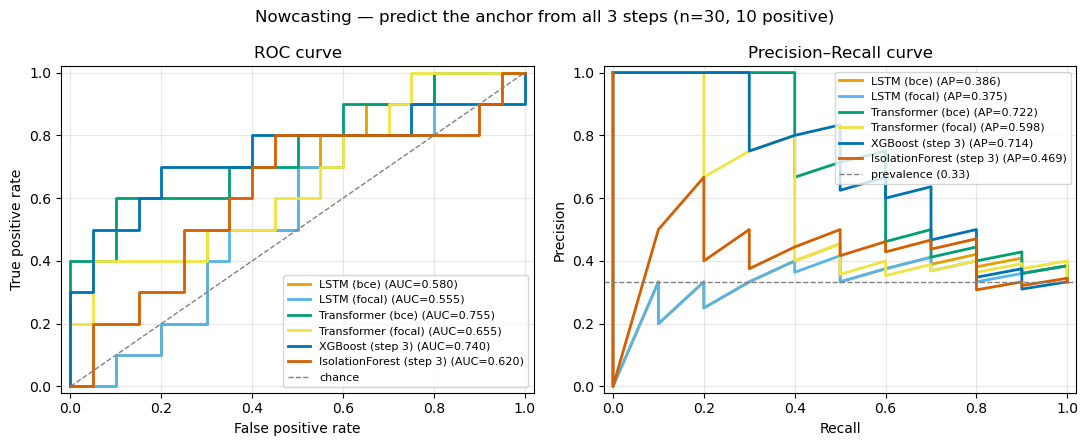

In [12]:
# --- Evaluation: reusable ROC + PR comparison plot ------------------------
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from src.utils.visualisation import OKABE_ITO   # project palette (colour-blind safe)

def plot_curves(scores, y_true, title):
    """One ROC + one PR axes comparing every model in `scores` on the same split.
    Reused by both the nowcasting and forecasting sections."""
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
    for i, (name, s) in enumerate(scores.items()):
        c = OKABE_ITO[i % len(OKABE_ITO)]
        fpr, tpr, _ = roc_curve(y_true, s)
        ax_roc.plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
        prec, rec, _ = precision_recall_curve(y_true, s)
        ax_pr.plot(rec, prec, color=c, lw=2, label=f"{name} (AP={average_precision_score(y_true, s):.3f})")
    # Reference lines: ROC chance diagonal, PR positive-prevalence (no-skill) line.
    ax_roc.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="chance")
    ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
    ax_roc.legend(loc="lower right", fontsize=8)
    ax_pr.axhline(y_true.mean(), ls="--", color="grey", lw=1, label=f"prevalence ({y_true.mean():.2f})")
    ax_pr.set(xlabel="Recall", ylabel="Precision", title="Precision–Recall curve")
    ax_pr.legend(loc="upper right", fontsize=8)
    for ax in (ax_roc, ax_pr):
        ax.grid(alpha=0.3); ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    fig.suptitle(title); fig.tight_layout(); plt.show()


plot_curves(MODEL_SCORES, yte,
            f"Nowcasting — predict the anchor from all 3 steps "
            f"(n={len(yte)}, {int(yte.sum())} positive)")

## Forecasting (predict the anchor from prior steps only)

The comparison above is *nowcasting*: the label is the node's status at the anchor (step 3) and every model — XGBoost included — sees step-3 features, which are **concurrent with the label**. That hands the non-sequential baseline the single most predictive slice, which is why it looks so strong there.

Here we make it a genuine **forecasting** task: predict the same anchor label using **only the prior steps (1 and 2)**, withholding step 3 entirely. The sequence models consume steps 1–2 as a sequence; the XGBoost baseline gets the *same* history flattened (2 × 90 = 180 features), so the only difference is sequential vs. not. Nodes with no prior observation (absent at both step 1 and 2) can't be forecast and are dropped from this cohort. Split, standardisation, losses and seeds are all reused unchanged, so any difference is attributable to withholding the concurrent step — this is where the temporal models should earn their keep.

In [13]:
# --- Forecasting: history only (steps 1-2), predict the anchor label ------
PRIOR = T - 1                                   # 2 prior steps; step 3 (anchor) withheld
has_tr = mtr[:, :PRIOR].any(1)                  # keep only nodes with >=1 prior observation
has_te = mte[:, :PRIOR].any(1)                  # (also avoids an all-masked row in the Transformer)
htr, hte = torch.as_tensor(has_tr), torch.as_tensor(has_te)
print(f"Forecasting cohort: train {has_tr.sum()}/{len(has_tr)}, test {has_te.sum()}/{len(has_te)} "
      f"(dropped nodes with no prior history)")

# Sequence models: reuse the standardized tensors, sliced to steps 1-2.
tr_fc = (Xtr_t[htr][:, :PRIOR, :], mtr_t[htr][:, :PRIOR], ytr_t[htr])
te_fc = (Xte_t[hte][:, :PRIOR, :], mte_t[hte][:, :PRIOR])
yte_fc = yte[has_te]

FORECAST_SCORES = {}   # separate store -> its own comparison plot
torch.manual_seed(SEED); train_eval(LSTMClassifier(),        name="LSTM (bce)",          train=tr_fc, test=te_fc, y_true=yte_fc, store=FORECAST_SCORES)
torch.manual_seed(SEED); train_eval(LSTMClassifier(),        name="LSTM (focal)",        loss="focal", train=tr_fc, test=te_fc, y_true=yte_fc, store=FORECAST_SCORES)
torch.manual_seed(SEED); train_eval(TransformerClassifier(), name="Transformer (bce)",   train=tr_fc, test=te_fc, y_true=yte_fc, store=FORECAST_SCORES)
torch.manual_seed(SEED); train_eval(TransformerClassifier(), name="Transformer (focal)", loss="focal", train=tr_fc, test=te_fc, y_true=yte_fc, store=FORECAST_SCORES)

# Fair non-sequential baseline: the SAME history (steps 1-2) flattened into a tree.
ytr_fc = ytr[has_tr]
Xtr_fc_xgb = X[idx_tr][has_tr][:, :PRIOR, :].reshape(has_tr.sum(), -1)   # raw features (trees: no scaling)
Xte_fc_xgb = X[idx_te][has_te][:, :PRIOR, :].reshape(has_te.sum(), -1)
spw_fc = (ytr_fc == 0).sum() / max(1, (ytr_fc == 1).sum())
xgb_fc = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.1, subsample=0.8,
    eval_metric="aucpr", scale_pos_weight=spw_fc, random_state=SEED,
)
xgb_fc.fit(Xtr_fc_xgb, ytr_fc)
record_scores("XGBoost (steps 1-2)", xgb_fc.predict_proba(Xte_fc_xgb)[:, 1],
              y_true=yte_fc, store=FORECAST_SCORES);

Forecasting cohort: train 116/120, test 29/30 (dropped nodes with no prior history)
  LSTM (bce): best val AUC-PR=0.571 @epoch 3 (stopped @33)
[LSTM (bce)] AUC-PR=0.619 (primary) | AUC-ROC=0.789
  LSTM (focal): best val AUC-PR=0.826 @epoch 159 (stopped @189)
[LSTM (focal)] AUC-PR=0.409 (primary) | AUC-ROC=0.578
  Transformer (bce): best val AUC-PR=0.688 @epoch 7 (stopped @37)
[Transformer (bce)] AUC-PR=0.537 (primary) | AUC-ROC=0.689
  Transformer (focal): best val AUC-PR=0.671 @epoch 6 (stopped @36)
[Transformer (focal)] AUC-PR=0.536 (primary) | AUC-ROC=0.678
[XGBoost (steps 1-2)] AUC-PR=0.526 (primary) | AUC-ROC=0.722


### Isolation Forest (forecasting baseline)

The same unsupervised anomaly detector, now on the **steps-1-2 history only** (identical to the forecasting XGBoost input), so the forecast comparison also carries a label-free baseline alongside the sequential models.

In [14]:
# --- Isolation Forest baseline (forecasting): same steps-1-2 history as XGBoost -----
# Unsupervised anomaly baseline on the SAME flattened prior-steps history the forecasting
# XGBoost uses. Fit on train, rank the test cohort by -score_samples.
iforest_fc = IsolationForest(n_estimators=200, random_state=SEED)
iforest_fc.fit(Xtr_fc_xgb)
record_scores("IsolationForest (steps 1-2)", -iforest_fc.score_samples(Xte_fc_xgb),
              y_true=yte_fc, store=FORECAST_SCORES);

[IsolationForest (steps 1-2)] AUC-PR=0.460 (primary) | AUC-ROC=0.683


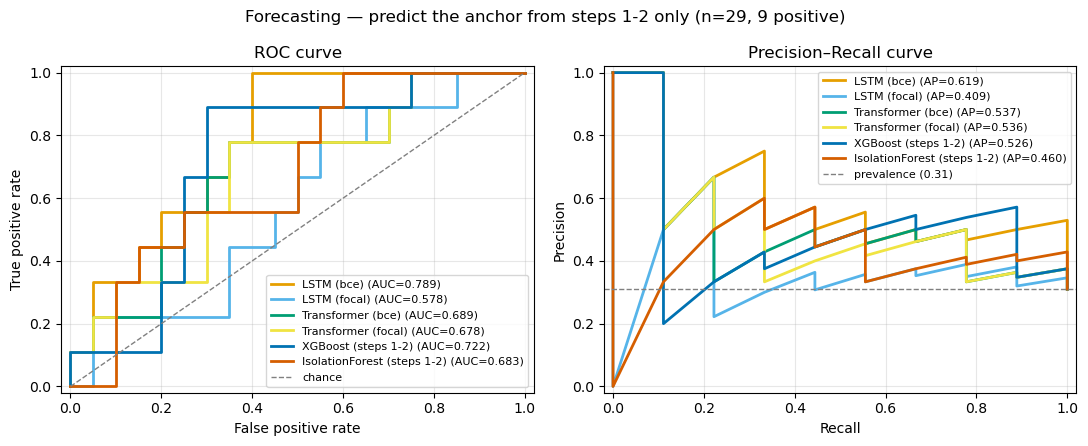

In [15]:
# --- Forecasting evaluation: same ROC + PR comparison, history-only inputs -
plot_curves(FORECAST_SCORES, yte_fc,
            f"Forecasting — predict the anchor from steps 1-2 only "
            f"(n={len(yte_fc)}, {int(yte_fc.sum())} positive)")